<a href="https://colab.research.google.com/github/skd9/astroid/blob/main/asteroid_families_lean_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Asteroid families from orbital elements: does better feature engineering beat a better algorithm?

**Question.** Can a clustering algorithm recover known asteroid families from orbital elements, and what matters more:
the algorithm (HCM vs HDBSCAN) or the representation of the data (osculating vs proper elements)?

**Data.**
- `sbdb_numbered_asteroids.csv`: JPL Small-Body Database, 895,910 numbered asteroids (osculating orbits, H, albedo).
- `Proper25.zip`: 335 published family-membership files (Nesvorný et al.), the answer key.
- `proper_catalog24.dat`: published proper elements (Nesvorný et al. 2024), used only as a reference.
- `nbody_proper_elements.csv`: precomputed 1-Myr N-body proper elements for 100 asteroids (validation only).

**Pipeline.** clean (DR-1 to DR-5) → sample 150,000 → baseline HCM on osculating elements → feature engineering
(secular-theory proper elements, `proper_elements.py`) → HCM and HDBSCAN → evaluation and significance test → validation.

In [1]:
import io, re, zipfile, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.sparse.csgraph import connected_components
from scipy.stats import wilcoxon, mannwhitneyu
from sklearn.cluster import HDBSCAN
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.neighbors import radius_neighbors_graph
from proper_elements import secular_proper_elements          # analytic proper elements (see the module docstring)
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": .25})

SBDB, PROPER25_ZIP, CATALOGUE, NBODY = "sbdb_numbered_asteroids.csv", "Proper25.zip", "proper_catalog24.dat", "nbody_proper_elements.csv"
SEED, N_SAMPLE  = 1, 150_000
CUT_FULL        = 45.0                    # HCM cutoff (m/s) for the full main belt
MIN_MEMBERS     = 10                      # smallest group counted as a family
CUTOFFS         = [48, 64, 79, 95, 111]   # HCM sweep (m/s)
HDBSCAN_MCS     = [100]                   # min_cluster_size; [50, 100, 200] for a sweep (~100 s per run on 150,000)

In [2]:
# ---- shared helpers ----
GM_SUN, AU = 1.32712440018e20, 1.495978707e11

def zappala(a, e, sini, v):
    # Features whose Euclidean distance equals the Zappala velocity distance (m/s) at reference speed v.
    return np.column_stack([v * np.sqrt(1.25) * np.log(a), v * np.sqrt(2) * e, v * np.sqrt(2) * sini])

def hcm_labels(X, cutoff, min_members=MIN_MEMBERS):
    # HCM = single linkage cut at `cutoff`: link pairs closer than the cutoff, follow the chains.
    _, g = connected_components(radius_neighbors_graph(X, cutoff, n_jobs=-1), directed=False)
    size = np.bincount(g)
    return np.where(size[g] >= min_members, g, -1)

def score(truth, labels):
    # Per family: recall (share of members in its best group), purity (share of that group that is the family),
    # found = both >= 0.5. Overall: families found, ARI, NMI.
    t = pd.DataFrame({"family": np.asarray(truth), "c": np.asarray(labels)})
    csize = t.loc[t.c >= 0, "c"].value_counts(); rows = []
    for fam, m in t[t.family != "background"].groupby("family"):
        if len(m) < MIN_MEMBERS: continue
        ic = m.loc[m.c >= 0, "c"].value_counts()
        r, p = (0.0, 0.0) if ic.empty else (ic.max() / len(m), ic.max() / csize[ic.idxmax()])
        rows.append({"family": fam, "size": len(m), "recall": r, "purity": p,
                     "match": 0 if r + p == 0 else 2 * r * p / (r + p), "found": r >= .5 and p >= .5})
    fam = pd.DataFrame(rows)
    summ = {"families_found": int(fam.found.sum()), "families_scored": len(fam),
            "ARI": adjusted_rand_score(truth, labels), "NMI": normalized_mutual_info_score(truth, labels),
            "clustered_%": float(100 * np.mean(np.asarray(labels) >= 0))}
    return summ, fam

## 1. Data cleaning

| Rule | What it does |
|---|---|
| DR-1 | keep `class == "MBA"` and 2.0 ≤ a ≤ 3.5 AU |
| DR-2 | albedo outside 0.02–0.6 → missing |
| DR-3 | join SBDB to the family files on the asteroid number parsed from `full_name`; drop provisional-only members |
| DR-4 | asteroid in two families → keep the smaller, more specific one (tie-break: prefer a family whose parent body differs) |
| DR-5 | no family → `background` |

The number parser requires a `(` after the number, so a provisional name such as `2005 QQ87` is not read as asteroid 2005.

In [3]:
raw = pd.read_csv(SBDB, low_memory=False)
raw["number"] = raw.full_name.str.extract(r"^\s*(\d+)\s.*\(")[0].astype("Int64")
assert pd.Series([" 1 Ceres (A801 AA)", "2005 QQ87"]).str.extract(r"^\s*(\d+)\s.*\(")[0].isna().tolist() == [False, True]

df = raw[(raw["class"] == "MBA") & raw.a.between(2.0, 3.5)].reset_index(drop=True)               # DR-1
n_bad_alb = int((df.albedo.notna() & ~df.albedo.between(0.02, 0.6)).sum())
df["albedo"] = df.albedo.where(df.albedo.between(0.02, 0.6))                                        # DR-2
df["sin_i"] = np.sin(np.radians(df.i))
df = df.drop(columns="diameter")                       # derived from albedo and H: never a feature
print(f"SBDB: {len(raw):,} | DR-1 main belt: {len(df):,} | DR-2 albedos set missing: {n_bad_alb}")

SBDB: 895,910 | DR-1 main belt: 825,292 | DR-2 albedos set missing: 440


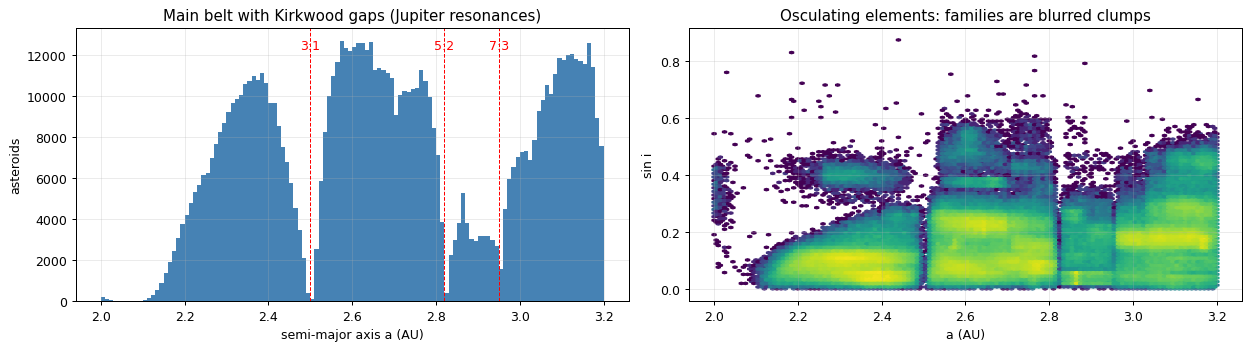

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(df.a, bins=np.arange(2.0, 3.21, 0.01), color="steelblue")
for g, lab in [(2.5, "3:1"), (2.82, "5:2"), (2.95, "7:3")]:
    ax[0].axvline(g, color="r", ls="--", lw=.8); ax[0].text(g, ax[0].get_ylim()[1] * .92, lab, color="r", ha="center")
ax[0].set(xlabel="semi-major axis a (AU)", ylabel="asteroids", title="Main belt with Kirkwood gaps (Jupiter resonances)")
ax[1].hexbin(df.a, df.sin_i, gridsize=120, bins="log", cmap="viridis", mincnt=1)
ax[1].set(xlabel="a (AU)", ylabel="sin i", title="Osculating elements: families are blurred clumps")
plt.tight_layout(); plt.show()

In [5]:
# ---- family files (answer key): DR-3, DR-4, DR-5 ----
cols = ["a_p", "e_p", "sin_i_p", "g_p", "s_p", "H_p", "n", "packed", "pdes"]
parts = []
with zipfile.ZipFile(PROPER25_ZIP) as z:
    for name in sorted(n for n in z.namelist() if re.search(r"\.fam\d*$", n, re.I)):
        d = pd.read_csv(io.StringIO(z.read(name).decode("utf-8", "replace")), sep=r"\s+", header=None,
                        comment="#", dtype=str, names=cols)
        parts.append(d.assign(family=re.sub(r"\.fam\d*$", "", name.rsplit("/", 1)[-1])))
mem = pd.concat(parts, ignore_index=True)
for c in ["a_p", "e_p", "sin_i_p"]: mem[c] = pd.to_numeric(mem[c], errors="coerce")
mem["size"] = mem.groupby("family").family.transform("size")                    # published size (all members)
mem["number"] = pd.to_numeric(mem.pdes.where(mem.pdes.str.fullmatch(r"\d+")), errors="coerce")
n_rows, n_prov = len(mem), int(mem.number.isna().sum())

mem = mem[mem.number.notna()].assign(number=lambda x: x.number.astype(int))     # DR-3: numbered members only
mem = mem[mem.number.isin(set(df.number))]                                        # DR-3: inside the DR-1 population

mem["parent"] = mem.family.str.extract(r"^[^_]+_(\d+)_")[0]                       # DR-4 with tie-break
mem["big_parent"] = mem.sort_values("size", ascending=False).groupby("number").parent.transform("first").reindex(mem.index)
mem["same_parent"] = (mem.parent == mem.big_parent).astype(int)
resolved = mem.sort_values(["number", "size", "same_parent", "family"]).drop_duplicates("number")

df = df.merge(resolved[["number", "family", "a_p", "e_p", "sin_i_p"]], on="number", how="left")
df["family"] = df.family.fillna("background")                                     # DR-5
print(f"family files: {n_rows:,} rows in {len(parts)} files | provisional-only dropped: {n_prov:,}")
print(f"after DR-4: {len(resolved):,} asteroids in {resolved.family.nunique()} families | background: {(df.family == 'background').sum():,}")

family files: 448,066 rows in 335 files | provisional-only dropped: 228,044
after DR-4: 192,011 asteroids in 311 families | background: 633,281


## 2. Sample and baseline

A random sample of 150,000 cleaned main-belt asteroids (seed 1). HCM needs only the pairs closer than the cutoff, so no
150,000 × 150,000 distance matrix is built. The full-belt cutoff of 45 m/s scales with sample density as (N_full / N)^(1/3).

In [6]:
hcm = df.sample(n=N_SAMPLE, random_state=SEED).sort_values("number").reset_index(drop=True)
V_REF = np.sqrt(GM_SUN / (hcm.a.median() * AU))                  # reference speed at the median a
CUTOFF = CUT_FULL * (len(df) / N_SAMPLE) ** (1 / 3)
print(f"sample: {len(hcm):,} | family members: {(hcm.family != 'background').sum():,} | "
      f"v_ref {V_REF:,.0f} m/s | HCM cutoff {CUTOFF:.0f} m/s")

X_osc = zappala(hcm.a, hcm.e, hcm.sin_i, V_REF)
hcm["hcm_osc"] = hcm_labels(X_osc, CUTOFF)
base, fam_osc = score(hcm.family, hcm.hcm_osc)
print("baseline, HCM on osculating elements:", {k: round(v, 3) for k, v in base.items()})

sample: 150,000 | family members: 35,296 | v_ref 18,228 m/s | HCM cutoff 79 m/s
baseline, HCM on osculating elements: {'families_found': 0, 'families_scored': 142, 'ARI': 0.165, 'NMI': np.float64(0.198), 'clustered_%': 32.721}


## 3. Feature engineering: proper elements

Osculating e and i oscillate over 10⁴–10⁶ years because the planets pull on every orbit, so members of one family drift
apart. Each orbit is the sum of a **forced** part, set by the planets and a, and a **free** part that family members share:

$$\text{proper } e = \left|\,\mathbf{e}_{\text{osc}} - \mathbf{e}_{\text{forced}}(a)\,\right|, \qquad \text{proper } \sin i = \left|\,\mathbf{i}_{\text{osc}} - \mathbf{i}_{\text{forced}}(a)\,\right|$$

`proper_elements.py` computes the forced vectors with 8-planet linear secular theory (Laplace–Lagrange). It takes 2 seconds for
150,000 asteroids. Below it is checked against the published catalogue, which nothing in the pipeline uses for training.

In [7]:
pe = secular_proper_elements(hcm.a, hcm.e, hcm.i, hcm.om, hcm.w)
hcm[["e_sec", "sini_sec"]] = pe[["e_pcalc", "sini_pcalc"]].values
hcm["a_sec"] = hcm.a

cat = pd.read_csv(CATALOGUE, sep=r"\s+", header=None, dtype={10: str, 11: str},
                  names=["a", "da", "e", "de", "sin_i", "dsin_i", "g", "s", "H", "n", "packed", "pdes"])
cat = cat[cat.pdes.str.fullmatch(r"\d+")].drop_duplicates("pdes")
cat = pd.DataFrame({"number": cat.pdes.astype(int).values, "a_cat": cat.a.values, "e_cat": cat.e.values, "sini_cat": cat.sin_i.values})
hcm = hcm.merge(cat, on="number", how="left")

c = hcm.dropna(subset=["a_cat"])
vv = np.sqrt(GM_SUN / (c.a_cat * AU))
dv = lambda a, e, s: (vv * np.sqrt(1.25 * ((a - c.a_cat) / c.a_cat)**2 + 2 * (e - c.e_cat)**2 + 2 * (s - c.sini_cat)**2)).median()
acc = pd.DataFrame({"median |de|": [(c.e - c.e_cat).abs().median(), (c.e_sec - c.e_cat).abs().median()],
                    "median |dsin i|": [(c.sin_i - c.sini_cat).abs().median(), (c.sini_sec - c.sini_cat).abs().median()],
                    "median error (m/s)": [dv(c.a, c.e, c.sin_i), dv(c.a_sec, c.e_sec, c.sini_sec)]},
                   index=["osculating", "secular theory"])
print(f"difference from the published catalogue, {len(c):,} sample asteroids:"); print(acc.round(4).to_string())

difference from the published catalogue, 107,527 sample asteroids:
                median |de|  median |dsin i|  median error (m/s)
osculating           0.0272           0.0116            778.2309
secular theory       0.0074           0.0017            216.0730


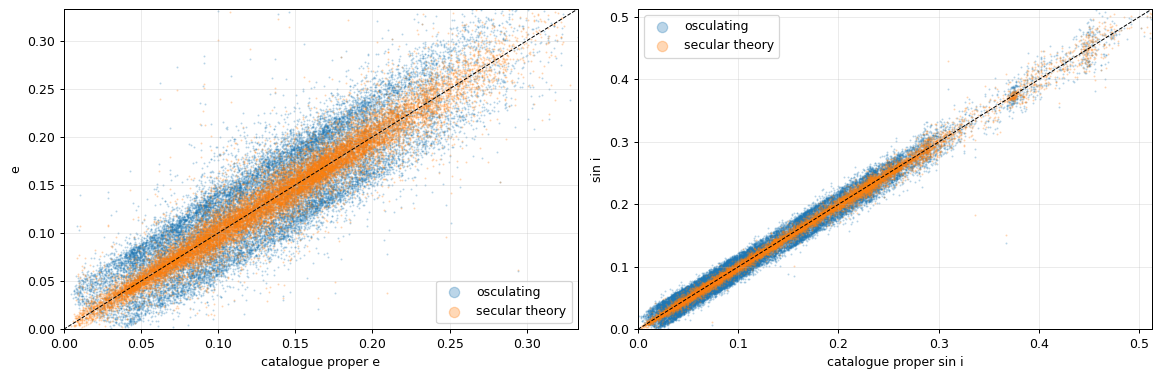

In [8]:
d = c.sample(20000, random_state=0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for a_, (o, p, r, lab) in zip(ax, [("e", "e_sec", "e_cat", "e"), ("sin_i", "sini_sec", "sini_cat", "sin i")]):
    a_.scatter(d[r], d[o], s=.3, alpha=.3, label="osculating", rasterized=True)
    a_.scatter(d[r], d[p], s=.3, alpha=.3, label="secular theory", rasterized=True)
    lim = [0, d[r].quantile(.995) * 1.1]; a_.plot(lim, lim, "k--", lw=.8)
    a_.set(xlim=lim, ylim=lim, xlabel=f"catalogue proper {lab}", ylabel=lab); a_.legend(markerscale=15)
plt.tight_layout(); plt.show()

## 4. Clustering: HCM and HDBSCAN on both representations

Same features (m/s), answer key and scoring for every run. HCM is swept over the cutoff. HDBSCAN uses `leaf` cluster
selection: the default `eom` prefers a few huge, stable groups and returns whole regions of the belt instead of families.

input         osculating  secular theory
cutoff (m/s)                            
48                     0              10
64                     0              17
79                     0              12
95                     0               8
111                    0               6


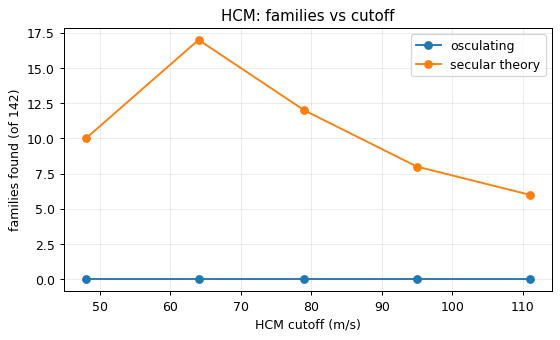

In [9]:
X_sec = zappala(hcm.a_sec, hcm.e_sec, hcm.sini_sec, V_REF)
INPUTS = {"osculating": X_osc, "secular theory": X_sec}

rows, labels = [], {}
for name, X in INPUTS.items():
    for cut in CUTOFFS:
        lab = hcm_labels(X, cut); s, _ = score(hcm.family, lab)
        rows.append({"method": "HCM", "input": name, "param": f"cutoff {cut} m/s", "value": cut, "found": s["families_found"], "ARI": s["ARI"]})
        labels[("HCM", name, cut)] = lab
sweep_hcm = pd.DataFrame(rows)
print(sweep_hcm.pivot(index="value", columns="input", values="found").rename_axis("cutoff (m/s)").to_string())

fig, ax = plt.subplots(figsize=(7, 3.8))
for name, g in sweep_hcm.groupby("input"):
    ax.plot(CUTOFFS, g.found, marker="o", label=name)
ax.set(xlabel="HCM cutoff (m/s)", ylabel=f"families found (of {s['families_scored']})", title="HCM: families vs cutoff"); ax.legend()
plt.show()

In [10]:
for name, X in INPUTS.items():
    for mcs in HDBSCAN_MCS:
        lab = HDBSCAN(min_cluster_size=mcs, min_samples=10, cluster_selection_method="leaf", copy=True).fit_predict(X)
        s, _ = score(hcm.family, lab)
        rows.append({"method": "HDBSCAN", "input": name, "param": f"min_cluster_size {mcs}", "value": mcs, "found": s["families_found"], "ARI": s["ARI"]})
        labels[("HDBSCAN", name, mcs)] = lab
results = pd.DataFrame(rows)
best = results.loc[results.groupby(["method", "input"]).found.idxmax()].set_index(["method", "input"])
print(best.drop(columns="value").round(3).to_string())

                                       param  found    ARI
method  input                                             
HCM     osculating             cutoff 48 m/s      0  0.024
        secular theory         cutoff 64 m/s     17  0.383
HDBSCAN osculating      min_cluster_size 100      3  0.134
        secular theory  min_cluster_size 100     19  0.332


In [11]:
key = lambda m, i: (m, i, int(best.loc[(m, i), "value"]))
for m in ["HCM", "HDBSCAN"]:
    for i, tag in [("osculating", "osc"), ("secular theory", "sec")]:
        hcm[f"{m.lower()}_{tag}_best"] = labels[key(m, i)]
_, f_hcm = score(hcm.family, hcm.hcm_sec_best); _, f_hdb = score(hcm.family, hcm.hdbscan_sec_best)
both = f_hcm.set_index("family").found.rename("HCM").to_frame().join(f_hdb.set_index("family").found.rename("HDBSCAN"))
print("secular theory, families found by both:", int((both.HCM & both.HDBSCAN).sum()),
      "| HCM only:", int((both.HCM & ~both.HDBSCAN).sum()), "| HDBSCAN only:", int((~both.HCM & both.HDBSCAN).sum()),
      "| either:", int((both.HCM | both.HDBSCAN).sum()))
print("HDBSCAN only:", both[~both.HCM & both.HDBSCAN].index.tolist())
print("HCM only:    ", both[both.HCM & ~both.HDBSCAN].index.tolist())

secular theory, families found by both: 8 | HCM only: 9 | HDBSCAN only: 11 | either: 28
HDBSCAN only: ['highi_148_Gallia', 'highi_25_Phocaea', 'highi_31_Euphrosyne', 'highi_480_Hansa', 'middle_128_Nemesis', 'middle_1644_Rafita', 'middle_569_Misa', 'middle_6468_Welzenbach', 'middle_847_Agnia', 'outer_10_Hygiea', 'prist_627_Charis']
HCM only:     ['inner_302_Clarissa', 'inner_4_Vesta', 'middle_3815_Konig', 'middle_396_Aeolia', 'middle_668_Dora', 'outer_1332_Marconia', 'outer_283_Emma', 'prist_1189_Terentia', 'prist_18405_1993FY12']


## 5. Evaluation: is the improvement significant?

Each family is scored with both representations, so the samples are paired: the Wilcoxon signed-rank test is the right
test (Mann–Whitney, which assumes independent samples, is shown for comparison). One-sided: secular theory > osculating.

In [12]:
_, f_o = score(hcm.family, hcm.hcm_osc)          # HCM, osculating, rule cutoff
_, f_s = score(hcm.family, hcm.hcm_sec_best)     # HCM, secular theory, best cutoff
pair = f_s.set_index("family")[["match"]].join(f_o.set_index("family")[["match"]], lsuffix="_sec", rsuffix="_osc")
w = wilcoxon(pair.match_sec, pair.match_osc, alternative="greater")
u = mannwhitneyu(pair.match_sec, pair.match_osc, alternative="greater")
print(f"{len(pair)} families | median match score: secular {pair.match_sec.median():.3f} vs osculating {pair.match_osc.median():.3f}")
print(f"Wilcoxon signed-rank (paired) p = {w.pvalue:.1e} | Mann-Whitney U p = {u.pvalue:.1e}")

142 families | median match score: secular 0.053 vs osculating 0.020
Wilcoxon signed-rank (paired) p = 1.6e-11 | Mann-Whitney U p = 8.8e-03


## 6. Validation: how far could better proper elements go?

Two reference points, both outside the main pipeline:
- **N-body proper elements** for 100 asteroids (Sun + 8 planets integrated for 1 Myr, frequency analysis; precomputed,
  ~35 min per 100 asteroids). They show how much accuracy secular theory leaves on the table.
- **HCM on the published catalogue elements**, on the sample asteroids that have them: the ceiling for any input.

In [13]:
nb = pd.read_csv(NBODY)
vv = np.sqrt(GM_SUN / (nb.a_pc * AU))
err = lambda a, e, s: vv * np.sqrt(1.25 * ((a - nb.a_pc) / nb.a_pc)**2 + 2 * (e - nb.e_pc)**2 + 2 * (s - nb.sini_pc)**2)
val = pd.DataFrame({"median error (m/s)": [err(nb.a, nb.e, nb.sin_i).median(), err(nb.a_pcalc, nb.e_pcalc, nb.sini_pcalc).median(),
                                           err(nb.a_pnb, nb.e_pnb, nb.sini_pnb).median()]},
                   index=["osculating", "secular theory", "N-body (Sun + 8 planets)"])
print(f"{len(nb)} asteroids vs the published catalogue:"); print(val.round(1).to_string())

sub = hcm.dropna(subset=["a_cat"]).reset_index(drop=True)
n_full_cat = int(df.number.isin(cat.number).sum())
cut_sub = CUT_FULL * (n_full_cat / len(sub)) ** (1 / 3)
ceil = {}
for name, (a, e, s) in {"osculating": ("a", "e", "sin_i"), "secular theory": ("a_sec", "e_sec", "sini_sec"),
                        "catalogue": ("a_cat", "e_cat", "sini_cat")}.items():
    ceil[name] = score(sub.family, hcm_labels(zappala(sub[a], sub[e], sub[s], V_REF), cut_sub))[0]["families_found"]
print(f"\nHCM on the {len(sub):,} sample asteroids with catalogue values (cutoff {cut_sub:.0f} m/s), families found:", ceil)

100 asteroids vs the published catalogue:
                          median error (m/s)
osculating                             812.2
secular theory                         249.4
N-body (Sun + 8 planets)                26.4

HCM on the 107,527 sample asteroids with catalogue values (cutoff 79 m/s), families found: {'osculating': 1, 'secular theory': 19, 'catalogue': 53}


## 7. Conclusions and limitations

**Results**
- **The representation decides the result.** On osculating elements HCM finds no families and HDBSCAN almost none;
  on secular-theory proper elements HCM finds 17 and HDBSCAN 19 (of 142).
- **The algorithms are complementary.** HCM recovers small, compact families; HDBSCAN recovers large or spread-out ones
  in crowded regions. Together they find 28 different families.
- **The improvement is significant:** paired Wilcoxon test on the per-family match score, p ≈ 10⁻¹¹.
- **Better features would help further.** N-body proper elements are ~10× more accurate than secular theory (26 vs 249 m/s
  median error), and HCM on the published catalogue elements finds 53 families on its rows.

**Limitations**
- *Circularity:* the Proper25 answer key was itself built by HCM on catalogue proper elements, so agreement with it is
  partly expected; the catalogue result is an upper bound, not an independent discovery.
- *Sampling:* 150,000 of 825,292 asteroids (18%) thins small families below the 10-member threshold.
- *Answer key:* DR-3 drops provisional-only members (51% of catalogue rows, the faint end of each family), and
  `background` mixes true non-members with unclassified asteroids.
- *Secular theory is linear:* it degrades at high inclination (sin i > 0.3) and near secular resonances.

## 8. Hypothesis tests (H1–H3)

All three use the labels from section 4 (best HCM cutoff and best HDBSCAN setting) and the per-family `score()`.

| ID | Hypothesis | Test | Supported if |
|---|---|---|---|
| H1 | Isolated high-inclination families are recovered better than families inside the dense belt | per-family recall, grouped by inclination region | high-inclination mean recall > low-inclination |
| H2 | Leaf-level HDBSCAN and a tuned HCM cutoff recover large families | recall for families with > 1,000 members | recall > 50% for most large families |
| H3 | Proper elements beat current SBDB orbits | ARI and NMI on both feature sets, same settings | higher ARI on proper elements |

In [14]:
# ---- H1: high-inclination vs low-inclination families (secular-theory input) ----
# Region from the Proper25 zone in the family name ("highi_..." = high-inclination zone).
h1 = []
for method, col in [("HCM", "hcm_sec_best"), ("HDBSCAN", "hdbscan_sec_best")]:
    _, f = score(hcm.family, hcm[col])
    f["region"] = np.where(f.family.str.startswith("highi_"), "high inclination", "low inclination (dense belt)")
    hi, lo = f.loc[f.region == "high inclination", "recall"], f.loc[f.region != "high inclination", "recall"]
    p = mannwhitneyu(hi, lo, alternative="greater").pvalue          # independent groups of families
    h1.append({"method": method, "high-i families": len(hi), "high-i mean recall": hi.mean(),
               "low-i families": len(lo), "low-i mean recall": lo.mean(), "Mann-Whitney p (high > low)": p,
               "H1 supported": hi.mean() > lo.mean()})
h1 = pd.DataFrame(h1).set_index("method"); print(h1.round(3).to_string())

         high-i families  high-i mean recall  low-i families  low-i mean recall  Mann-Whitney p (high > low)  H1 supported
method                                                                                                                    
HCM                   18               0.004             124              0.313                        1.000         False
HDBSCAN               18               0.402             124              0.376                        0.494          True


In [15]:
# ---- H2: recall for large families (> 1,000 members in the published family files) ----
LARGE = 1000
pub_size = mem.groupby("family")["size"].first()                    # published size, all members (before DR-3)
large = pub_size[pub_size > LARGE].index
h2 = {}
for method, col in [("HCM (tuned cutoff)", "hcm_sec_best"), ("HDBSCAN (leaf)", "hdbscan_sec_best")]:
    _, f = score(hcm.family, hcm[col])
    h2[method] = f[f.family.isin(large)].set_index("family").recall
h2 = pd.DataFrame(h2).sort_values("HCM (tuned cutoff)", ascending=False)
share = (h2 > 0.5).mean()
print(f"{len(h2)} large families (> {LARGE:,} published members) scored in the sample")
print(h2.round(2).to_string())
print("\nshare of large families with recall > 50%:", share.round(2).to_dict(),
      "| H2 supported (most = more than half):", (share > 0.5).to_dict())

55 large families (> 1,000 published members) scored in the sample
                         HCM (tuned cutoff)  HDBSCAN (leaf)
family                                                     
inner_135_Hertha                       1.00            0.61
prist_832_Karin                        1.00            1.00
middle_396_Aeolia                      1.00            1.00
middle_1726_Hoffmeister                1.00            0.99
prist_845_Naema                        0.97            0.99
outer_490_Veritas                      0.96            0.75
middle_128_Nemesis                     0.95            0.77
prist_158_Koronis                      0.94            0.98
inner_20_Massalia                      0.94            0.12
middle_847_Agnia                       0.92            0.86
middle_1128_Astrid                     0.90            0.98
outer_221_Eos                          0.89            0.22
middle_3815_Konig                      0.88            0.96
outer_283_Emma                   

In [16]:
# ---- H3: proper vs osculating elements, same settings ----
h3 = []
for (method, name, value), lab in labels.items():
    s, _ = score(hcm.family, lab)
    h3.append({"method": method, "setting": value, "input": name, "ARI": s["ARI"], "NMI": s["NMI"]})
h3 = pd.DataFrame(h3).pivot_table(index=["method", "setting"], columns="input", values=["ARI", "NMI"])
h3[("ARI", "proper - osc")] = h3[("ARI", "secular theory")] - h3[("ARI", "osculating")]
print(h3.round(3).to_string())
print("\nproper elements have the higher ARI at", int((h3[("ARI", "proper - osc")] > 0).sum()), "of", len(h3), "settings")

# bootstrap 95% interval of the ARI difference at the Part 2 cutoff (asteroids resampled with replacement)
lab_o, lab_s = labels[("HCM", "osculating", 79)], labels[("HCM", "secular theory", 79)]
rng = np.random.default_rng(SEED); truth = hcm.family.values; diffs = []
for _ in range(200):
    i = rng.integers(0, len(hcm), len(hcm))
    diffs.append(adjusted_rand_score(truth[i], lab_s[i]) - adjusted_rand_score(truth[i], lab_o[i]))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"HCM at 79 m/s: ARI difference (proper - osculating) 95% CI [{lo:.3f}, {hi:.3f}] | H3 supported: {lo > 0}")

                       ARI                       NMI                         ARI
input           osculating secular theory osculating secular theory proper - osc
method  setting                                                                 
HCM     48           0.024          0.312      0.027          0.293        0.287
        64           0.149          0.383      0.139          0.373        0.234
        79           0.167          0.246      0.197          0.337        0.079
        95           0.092          0.119      0.234          0.319        0.027
        111          0.026          0.045      0.211          0.291        0.020
HDBSCAN 100          0.134          0.332      0.166          0.392        0.198

proper elements have the higher ARI at 6 of 6 settings
HCM at 79 m/s: ARI difference (proper - osculating) 95% CI [0.074, 0.084] | H3 supported: True


In [17]:
# Merge the best-performing labels (from the 150,000 sample) back to the main DataFrame
# and save them to a new CSV file alongside the original asteroid features

# Create a lightweight DataFrame with the sample results
clustering_results = hcm[["number", "hcm_sec_best", "hdbscan_sec_best"]]

# Merge these results back into the cleaned, full main-belt population (df)
output_df = df.merge(clustering_results, on="number", how="left")

# Fill NaN values for asteroids that were not in our random sample with -1 (unclustered)
output_df["hcm_sec_best"] = output_df["hcm_sec_best"].fillna(-1).astype(int)
output_df["hdbscan_sec_best"] = output_df["hdbscan_sec_best"].fillna(-1).astype(int)

# Save to a CSV file
output_filename = "asteroids_with_labels.csv"
output_df.to_csv(output_filename, index=False)
print(f"Successfully saved {len(output_df):,} asteroids with clustering labels to {output_filename}")

# Display sample of the results
display(output_df[output_df["hcm_sec_best"] >= 0][["full_name", "a", "e", "i", "family", "hcm_sec_best", "hdbscan_sec_best"]].head())

Successfully saved 825,292 asteroids with clustering labels to asteroids_with_labels.csv


,full_name,a,e,i,family,hcm_sec_best,hdbscan_sec_best
9,10 Hygiea (A849 GA),3.151,0.1067,3.83,outer_10_Hygiea,1,15
14,15 Eunomia (A851 OA),2.642,0.1878,11.76,middle_15_Eunomia,4,39
61,62 Erato (A860 RD),3.129,0.1678,2.24,outer_24_Themis,9,12
148,158 Koronis (A876 AA),2.869,0.0537,1.01,prist_832_Karin,19,48
171,182 Elsa (A878 CC),2.416,0.1864,2.01,inner_20_Massalia,23,-1


In [ ]:
# Part 9 · Visualizing the clusters. Paste after Part 8 of asteroid_families_lean.ipynb (one cell per "# %%").
# %% [markdown]
# ## 9. Visualizing the clusters
#
# Three views of the best HCM and HDBSCAN labels from section 4:
# 1. **Cluster maps** in a vs sin i: the 15 largest groups in colour, everything else grey.
# 2. **Where each large family's members went:** best group, other groups, or noise.
# 3. **How mixed each group is:** number of different Proper25 families inside each of the 10 largest groups.

# %%
# ---- 1. cluster maps: osculating vs secular theory, HCM vs HDBSCAN ----
panels = [("HCM", "osculating", "hcm_osc_best", "a", "sin_i"), ("HCM", "secular theory", "hcm_sec_best", "a_sec", "sini_sec"),
          ("HDBSCAN", "osculating", "hdbscan_osc_best", "a", "sin_i"), ("HDBSCAN", "secular theory", "hdbscan_sec_best", "a_sec", "sini_sec")]
fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True, sharey=True)
for ax, (method, inp, col, a, s) in zip(axes.ravel(), panels):
    lab = hcm[col]; top = lab[lab >= 0].value_counts().index[:15]
    other = ~lab.isin(top)
    ax.scatter(hcm.loc[other, a], hcm.loc[other, s], s=0.2, c="lightgrey", rasterized=True)
    for k, g in enumerate(top):
        m = lab == g
        ax.scatter(hcm.loc[m, a], hcm.loc[m, s], s=0.6, color=plt.cm.tab20(k % 20), rasterized=True)
    found = score(hcm.family, lab)[0]["families_found"]
    ax.set(title=f"{method}, {inp}: {found} families found", xlim=(2.1, 3.25), ylim=(0, 0.45))
for ax in axes[1]: ax.set_xlabel("a (AU)")
for ax in axes[:, 0]: ax.set_ylabel("sin i")
plt.suptitle("15 largest groups in colour, all other asteroids grey", fontsize=14); plt.tight_layout(); plt.show()



In [ ]:
# Part 9 · Visualizing the clusters. Paste after Part 8 of asteroid_families_lean.ipynb (one cell per "# %%").

# %%
# ---- 2. where did each large family's members go? (secular theory) ----
top_fams = hcm.loc[hcm.family != "background", "family"].value_counts().index[:10]
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
for ax, (method, col) in zip(axes, [("HCM", "hcm_sec_best"), ("HDBSCAN", "hdbscan_sec_best")]):
    rows = []
    for f in top_fams:
        lab = hcm.loc[hcm.family == f, col]; inc = lab[lab >= 0]
        best = (inc == inc.value_counts().idxmax()).sum() if len(inc) else 0
        rows.append({"family": f.split("_", 2)[-1], "best group": best / len(lab),
                     "other groups": (len(inc) - best) / len(lab), "noise": (lab < 0).mean()})
    pd.DataFrame(rows).set_index("family").plot(kind="bar", stacked=True, ax=ax, color=["#14897A", "#E39B2D", "#C9CED8"], width=0.75)
    ax.set(title=f"{method} (secular theory): members of the 10 largest families", xlabel="", ylabel="share of the family's members")
    ax.tick_params(axis="x", rotation=45); ax.get_legend().remove()
fig.legend(["best group", "other groups", "noise"], loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()


In [ ]:

# %%
# ---- 3. how mixed is each group? distinct families inside the 10 largest groups (secular theory) ----
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (method, col, colour) in zip(axes, [("HCM", "hcm_sec_best", "#14897A"), ("HDBSCAN", "hdbscan_sec_best", "#E39B2D")]):
    lab = hcm[col]; top = lab[lab >= 0].value_counts().index[:10]
    sub = hcm[lab.isin(top)]
    n_fam = sub[sub.family != "background"].groupby(col).family.nunique().reindex(top).fillna(0)
    share_bg = sub.groupby(col).family.apply(lambda f: (f == "background").mean()).reindex(top)
    ax.bar(range(10), n_fam.values, color=colour)
    for k, (n, b) in enumerate(zip(n_fam.values, share_bg.values)):
        ax.text(k, n + 0.3, f"{b:.0%} bg", ha="center", fontsize=8, color="#5B6B8C")
    ax.set(xticks=range(10), xticklabels=[f"#{k+1}" for k in range(10)], xlabel="group (largest first)",
           ylabel="distinct Proper25 families", title=f"{method}: families mixed into each large group", ylim=(0, n_fam.max() + 1.5))
plt.tight_layout(); plt.show()
print("A pure family group holds 1 family; labels show the share of background asteroids in each group.")